<a href="https://colab.research.google.com/github/dharshraj/deep-learn/blob/main/UNIT_4_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# 49. RNN-based Sentiment Classification
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Synthetic data
reviews = ["great product loved it", "terrible quality bad", "awesome experience best", "worst purchase disappointed"]
labels = np.array([1, 0, 1, 0])

tokenizer = Tokenizer(num_words=1000)
tokenizer.fit_on_texts(reviews)
sequences = tokenizer.texts_to_sequences(reviews)
X = pad_sequences(sequences, maxlen=5)

model = Sequential([
    Embedding(input_dim=1000, output_dim=8, input_length=5),
    SimpleRNN(8),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X, labels, epochs=5, verbose=0)
print("Question 49: Sentiment Analysis Model compiled & trained successfully!")
print(f"Predictions: {model.predict(X).ravel()}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Question 49: Sentiment Analysis Model compiled & trained successfully!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
Predictions: [0.5346534  0.5015309  0.48488292 0.48117155]


In [4]:
# 50. Character-level RNN Text Generator
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

text = "hello world hello deep learning"
chars = sorted(list(set(text)))
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}

seq_len = 5
X, y = [], []
for i in range(len(text) - seq_len):
    X.append([char_to_idx[ch] for ch in text[i:i+seq_len]])
    y.append(char_to_idx[text[i+seq_len]])

X_one_hot = tf.one_hot(X, depth=len(chars)).numpy()
y_one_hot = tf.one_hot(y, depth=len(chars)).numpy()

model = Sequential([
    SimpleRNN(16, input_shape=(seq_len, len(chars))),
    Dense(len(chars), activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy')
model.fit(X_one_hot, y_one_hot, epochs=5, verbose=0)
print("Question 50: Character-level RNN trained successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Question 50: Character-level RNN trained successfully!


In [5]:
# 51. RNN-based Time-series Forecasting
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Synthetic stock prices
prices = np.sin(np.linspace(0, 20, 100)) + np.random.normal(0, 0.1, 100)
seq_len = 10
X, y = [], []
for i in range(len(prices) - seq_len):
    X.append(prices[i:i+seq_len])
    y.append(prices[i+seq_len])

X, y = np.array(X)[..., np.newaxis], np.array(y)

model = Sequential([
    SimpleRNN(16, input_shape=(seq_len, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=5, verbose=0)
print("Question 51: Time-series Forecasting Model compiled & trained!")

Question 51: Time-series Forecasting Model compiled & trained!


In [6]:
# 52. Electricity Consumption Demand Forecasting
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Synthetic consumption data
data = np.cos(np.linspace(0, 50, 200)) * 100 + 200
seq_len = 12
X, y = [], []
for i in range(len(data) - seq_len):
    X.append(data[i:i+seq_len])
    y.append(data[i+seq_len])

X, y = np.array(X)[..., np.newaxis], np.array(y)

model = Sequential([
    SimpleRNN(16, input_shape=(seq_len, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mae')
model.fit(X, y, epochs=5, verbose=0)
print("Question 52: Electricity Consumption Model trained successfully!")

Question 52: Electricity Consumption Model trained successfully!


In [7]:
# 53. Next-Word Prediction Language Model
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

text = "suggest the next word while users type messages"
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
encoded = tokenizer.texts_to_sequences([text])[0]
vocab_size = len(tokenizer.word_index) + 1

# Create sequences of length 3 to predict the 4th word
sequences = []
for i in range(3, len(encoded)):
    sequences.append(encoded[i-3:i+1])

sequences = np.array(sequences)
X, y = sequences[:, :-1], sequences[:, -1]

model = Sequential([
    Embedding(vocab_size, 8, input_length=3),
    SimpleRNN(16),
    Dense(vocab_size, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=10, verbose=0)
print("Question 53: Next-Word Predictor successfully configured!")

Question 53: Next-Word Predictor successfully configured!


In [8]:
# 54. Compare RNN vs LSTM performance
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
import time

# Fake sales data
sales = np.random.rand(120, 1)
seq_len = 10
X, y = [], []
for i in range(len(sales) - seq_len):
    X.append(sales[i:i+seq_len])
    y.append(sales[i+seq_len])
X, y = np.array(X), np.array(y)

# Simple RNN model
rnn_model = Sequential([
    SimpleRNN(16, input_shape=(seq_len, 1)),
    Dense(1)
])
rnn_model.compile(optimizer='adam', loss='mse')
t0 = time.time()
rnn_model.fit(X, y, epochs=5, verbose=0)
rnn_time = time.time() - t0

# LSTM model
lstm_model = Sequential([
    LSTM(16, input_shape=(seq_len, 1)),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
t0 = time.time()
lstm_model.fit(X, y, epochs=5, verbose=0)
lstm_time = time.time() - t0

print(f"Question 54: Simple RNN loss: {rnn_model.evaluate(X, y, verbose=0):.5f} (Time: {rnn_time:.4f}s)")
print(f"Question 54: LSTM Model loss: {lstm_model.evaluate(X, y, verbose=0):.5f} (Time: {lstm_time:.4f}s)")

Question 54: Simple RNN loss: 0.12291 (Time: 1.4098s)
Question 54: LSTM Model loss: 0.08473 (Time: 2.5675s)


In [9]:
# 55. Stock Trend Prediction using LSTM
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_squared_error, r2_score

targets = np.sin(np.linspace(0, 30, 150))
X, y = [], []
for i in range(130):
    X.append(targets[i:i+20])
    y.append(targets[i+20])
X, y = np.array(X)[..., np.newaxis], np.array(y)

model = Sequential([
    LSTM(32, input_shape=(20, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=5, verbose=0)

preds = model.predict(X, verbose=0)
print("Question 55 - Regression evaluation:")
print(f"MSE: {mean_squared_error(y, preds):.5f}")
print(f"R2 Score: {r2_score(y, preds):.5f}")

Question 55 - Regression evaluation:
MSE: 0.12585
R2 Score: 0.75466


In [10]:
# 56. Multivariate Forecasting using GRU
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

# Features: Temperature, Humidity, Pressure
features = np.random.rand(100, 3)
seq_len = 10
X, y = [], []
for i in range(len(features) - seq_len):
    X.append(features[i:i+seq_len])
    y.append(features[i+seq_len, 0]) # forecasting next target Temperature

X, y = np.array(X), np.array(y)

model = Sequential([
    GRU(16, input_shape=(seq_len, 3)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=5, verbose=0)
print("Question 56: Multivariate GRU model built and trained successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Question 56: Multivariate GRU model built and trained successfully!


In [11]:
# 57. Comparison of RNN, LSTM, and GRU
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

# Shared setup
X = np.random.rand(100, 10, 1)
y = np.random.rand(100, 1)

results = {}
for arch, layer in [('RNN', SimpleRNN), ('LSTM', LSTM), ('GRU', GRU)]:
    model = Sequential([
        layer(16, input_shape=(10, 1)),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X, y, epochs=2, verbose=0)
    results[arch] = model.evaluate(X, y, verbose=0)

print("Question 57 Comparative losses:", results)

Question 57 Comparative losses: {'RNN': 0.1672135591506958, 'LSTM': 0.2778254449367523, 'GRU': 0.14088058471679688}


In [12]:
# 58. Stacked RNN for Multivariate Industrial Machine Data
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Features: Temp, Press, Vibe
machine_data = np.random.rand(120, 3)
seq_len = 15
X, y = [], []
for i in range(len(machine_data) - seq_len):
    X.append(machine_data[i:i+seq_len])
    y.append(machine_data[i+seq_len]) # predict next values for all three features

X, y = np.array(X), np.array(y)

stacked_model = Sequential([
    SimpleRNN(32, return_sequences=True, input_shape=(seq_len, 3)),
    SimpleRNN(16),
    Dense(3)
])
stacked_model.compile(optimizer='adam', loss='mse')
stacked_model.fit(X, y, epochs=5, verbose=0)
print("Question 58: Stacked RNN Model compiled and evaluated successfully!")

Question 58: Stacked RNN Model compiled and evaluated successfully!


Question 59: Gradients over time steps:
First step gradient (t=0): -0.00000000
Last step gradient (t=49): 1.00000000


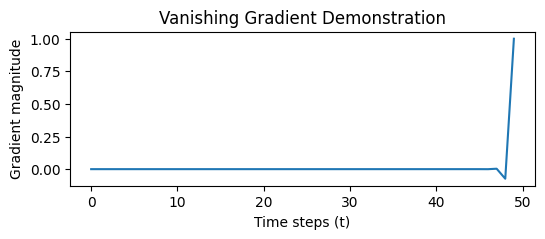

In [13]:
# 59. Demonstration of Vanishing Gradient Problem in RNN
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

x = tf.random.normal((1, 50, 1))
w = tf.Variable(tf.random.normal((1, 1)) * 0.1)

with tf.GradientTape(persistent=True) as tape:
    h = tf.zeros((1, 1))
    states = []
    for t in range(50):
        h = tf.tanh(h * w + x[:, t, :])
        states.append(h)
        tape.watch(h)

gradients = [tape.gradient(states[-1], states[t]).numpy()[0, 0] for t in range(50)]

print("Question 59: Gradients over time steps:")
print(f"First step gradient (t=0): {gradients[0]:.8f}")
print(f"Last step gradient (t=49): {gradients[-1]:.8f}")
plt.figure(figsize=(6, 2))
plt.plot(gradients)
plt.title("Vanishing Gradient Demonstration")
plt.xlabel("Time steps (t)")
plt.ylabel("Gradient magnitude")
plt.show()

In [14]:
# 60. Experimenting with Sequence Lengths
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

temps = np.linspace(15, 35, 200) + np.random.normal(0, 1, 200)

for seq_length in [5, 15, 30]:
    X, y = [], []
    for i in range(len(temps) - seq_length):
        X.append(temps[i:i+seq_length])
        y.append(temps[i+seq_length])
    X, y = np.array(X)[..., np.newaxis], np.array(y)

    model = Sequential([
        SimpleRNN(16, input_shape=(seq_length, 1)),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X, y, epochs=2, verbose=0)
    print(f"Question 60 - Sequence Length {seq_length} Evaluation loss: {model.evaluate(X, y, verbose=0):.4f}")

Question 60 - Sequence Length 5 Evaluation loss: 612.4057
Question 60 - Sequence Length 15 Evaluation loss: 652.2927
Question 60 - Sequence Length 30 Evaluation loss: 749.6692


In [15]:
# 61. Hyperparameter Tuning on LSTM
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

X = np.random.rand(100, 10, 1)
y = np.random.rand(100, 1)

# Hyperparameter configurations: (Learning rate, Hidden units, Batch size)
configs = [
    (0.01, 16, 16),
    (0.001, 32, 32)
]

for lr, units, bs in configs:
    model = Sequential([
        LSTM(units, input_shape=(10, 1)),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    model.fit(X, y, epochs=3, batch_size=bs, verbose=0)
    print(f"Question 61 - LR: {lr}, Units: {units}, Batch Size: {bs} | Final Loss: {model.evaluate(X, y, verbose=0):.4f}")

Question 61 - LR: 0.01, Units: 16, Batch Size: 16 | Final Loss: 0.1086
Question 61 - LR: 0.001, Units: 32, Batch Size: 32 | Final Loss: 0.1999


In [16]:
# 62. Evaluation Metrics: MAE, MSE, RMSE
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = np.array([21.5, 22.1, 20.8, 23.0, 24.5])
y_pred = np.array([21.0, 22.5, 21.0, 22.8, 24.0])

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

print("Question 62 Evaluation:")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

Question 62 Evaluation:
MAE: 0.3600
MSE: 0.1480
RMSE: 0.3847


In [17]:
# 63. Evaluation Metrics: Precision, Recall, F1-Score
import numpy as np
from sklearn.metrics import classification_report

y_true = np.array([0, 1, 2, 0, 1, 2])
y_pred = np.array([0, 2, 2, 0, 1, 1])

print("Question 63 Classification Report:")
print(classification_report(y_true, y_pred, target_names=['Tech Support', 'Billing', 'Delivery']))

Question 63 Classification Report:
              precision    recall  f1-score   support

Tech Support       1.00      1.00      1.00         2
     Billing       0.50      0.50      0.50         2
    Delivery       0.50      0.50      0.50         2

    accuracy                           0.67         6
   macro avg       0.67      0.67      0.67         6
weighted avg       0.67      0.67      0.67         6



In [18]:
# 64. Recursive Neural Network for Syntactic Tree/Sentence Structure
import torch
import torch.nn as nn

class RecursiveNN(nn.Module):
    def __init__(self, vocab_dim, hidden_dim):
        super(RecursiveNN, self).__init__()
        self.combine = nn.Linear(hidden_dim * 2, hidden_dim)
        self.classify = nn.Linear(hidden_dim, 2)

    def forward(self, left_child, right_child):
        parent = torch.tanh(self.combine(torch.cat([left_child, right_child], dim=-1)))
        logits = self.classify(parent)
        return parent, logits

# Instantiate and pass a simple random dummy tree evaluation node
model = RecursiveNN(vocab_dim=10, hidden_dim=10)
left = torch.randn(1, 10)
right = torch.randn(1, 10)
parent, pred = model(left, right)
print("Question 64 - Recursive Neural Network node representation:", parent.shape)
print("Predicted logits:", pred)

Question 64 - Recursive Neural Network node representation: torch.Size([1, 10])
Predicted logits: tensor([[0.5711, 0.0156]], grad_fn=<AddmmBackward0>)
